# Tiamat
**Aluno: Gabriel de Oliveira Paiva**

## Configurações Iniciais e importações

Vamos importar as ferramentas necessárias para fazermos nosso trabaho!

In [50]:
import gc
import os
import time
import warnings
import optuna
import joblib
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.inspection import partial_dependence
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)
from pathlib import Path
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")

Definindo algumas configurações que iremos utilizar durante nosso trabalho

In [51]:
RANDOM_STATE = 42

# Configurações do Optuna
N_TRIALS = 100
ARQUIVO_DB = "optuna_generos_musicais.db" # Pra não otimizar tudo de novo
STORAGE = f"sqlite:///{ARQUIVO_DB}"
RECOMECAR_DO_ZERO = False                

N_CPU = os.cpu_count() or 1
N_JOBS_FINAL = max(1, N_CPU - 1)                # deixa 1 núcleo livre
TAMANHO_BLOCO_RF = 25                           # Limita a memória
ARQUIVO_CACHE = "cache_avaliacao_teste.joblib"  # Evitar ter que treinar tudo de novo
REAVALIAR = False                               

## Conhecendo nosso Dataset

Nosso dataset é sobre músicas!!! É composto por músicas reais, as informações foram coletadas por quem construiu o dataset diretamente do Spotify!

In [52]:
dataset = "dataset_musicas.csv"

df = pd.read_csv(dataset)

print("Formato:", df.shape)
df.head()

Formato: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

Vamos investigar as lacunas que o nosso dataset possui!

In [54]:
print("Valores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nNúmero de gêneros:", df["track_genre"].nunique())
df["track_genre"].value_counts().describe()

Valores nulos por coluna:
artists       1
album_name    1
track_name    1
dtype: int64

Número de gêneros: 114


count     114.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0
Name: count, dtype: float64

Vamos treinar nossos modelos para tentarmos classificar as músicas de acordo com os genêros classificados pela plataforma!

**Observações importantes**

 Isso é definido pelo `track_genre`e tem 114 classes possíveis! Pelo menos elas estão praticamente balanceadas!
Mais uma dificuldade será que uma mesma música pode estar integrada em gêneros diferentes, se distribuírmos os grupos de treino e teste de forma aleatória podemos sofrer com vazamento de dados! Isso será mais um ingrediente de dificuldade para nosso trabalho, vamos ver como isso poderá afetar nossos modelos!

In [55]:
COL_ALVO = "track_genre"
COL_GRUPO = "track_id"

Vamos escolher agora nossos atributos! Utilizaremos apenas informações que dizem respeito á música e sua repercussão na plataforma.

Não vamos utilizar nomes de artistas ou bandas nem nada que identifique e possa causar distoirções na análise de nossos modelos.

In [56]:
atributos = [
    "popularity", "duration_ms", "explicit", "danceability", "energy",
    "key", "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
    "time_signature",
]
print(f"{len(atributos)} atributos utilizados:")
print(atributos)

15 atributos utilizados:
['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


**X:** contém os atributos das músicas que serão utilizados para realizar as previsões.

**y_texto:** contém os gêneros musicais que queremos prever.

**grupos:** contém os identificadores das músicas, utilizados posteriormente para orientar a divisão dos conjuntos de dados.

Também convertemos a variável `explicit` de booleana para numérica, para mais fácil aplicação de nossos algoritmos

In [57]:
# Variáveis explicativas
X = df[atributos].copy()

# Converte valores booleanos para inteiros (True = 1, False = 0)
X["explicit"] = X["explicit"].astype(int)

# Variável que queremos prever
y_texto = df[COL_ALVO]

# Identificadores utilizados no agrupamento
grupos = df[COL_GRUPO]

Vamos utilizar o LabelEnconder para transformar nossos gêneros que estão em formato de texto em números para facilitar que nossos algoritmos consigam classificá-los

In [58]:
le = LabelEncoder()
y = le.fit_transform(y_texto)
print("Número de classes:", len(le.classes_))
print("Exemplos:", list(le.classes_[:8]))

Número de classes: 114
Exemplos: ['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass']


Vamos utilizar a ferramenta `StratifiedGroupKFold`para manter todas as linhas de um mesmo `track_id` no mesmo lado e tenta preservar a proporção entre gêneros. Usamos a primeira das 5 partes como teste.

In [59]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(sgkf.split(X, y, groups=grupos))

X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y[idx_treino], y[idx_teste]
grupos_treino = grupos.iloc[idx_treino].to_numpy()   # usado na validação cruzada do Optuna

# Garante que nenhuma música aparece nos dois conjuntos
assert set(grupos.iloc[idx_treino]).isdisjoint(set(grupos.iloc[idx_teste]))

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Treino: (91200, 15) | Teste: (22800, 15)


 **Floresta Aleatória** e o **Baseline** não precisam de Normalização.
 **Regressão Logística, SVM, KNN e Naive Bayes**  Usamos `StandardScaler` dentro de um `Pipeline`, ajustado somente no treino para evitar vazamento de dados

In [60]:
def normalização_padrão(modelo):
    return Pipeline([
        ("escala", StandardScaler()),
        ("modelo", modelo),
    ])

## Otimização de hiperparâmetros com Optuna

Para cada um dos modelos modelo o Optuna executará 100 tentativas.

**Validação cruzada agrupada:** cada tentativa é avaliada com `StratifiedGroupKFold` (3 partes) usando `track_id` como grupo, a mesma lógica da divisão treino/teste. Assim a acurácia de validação não é inflada por músicas repetidas em gêneros diferentes. A otimização usa apenas o conjunto de treino.

**Arquivo `.db`:** todas as tentativas são gravadas em `optuna_generos_musicais.db`. Se o estudo de um modelo já tem 100 tentativas concluídas, nada é reotimizado, o Optuna só lê o resultado. Se a execução for interrompida, ao rodar de novo ele continua de onde parou. Para refazer tudo do zero, use `RECOMECAR_DO_ZERO = True`

**SVM barato:** a busca do SVM roda em uma subamostra estratificada (≈10%) do treino e usa variantes lineares de SVM, que escalam bem com 114 classes. O modelo final é treinado no treino completo.

**Cache da avaliação final:** depois da otimização, o modelo final de cada algoritmo é treinado uma vez e as previsões no teste ficam em `cache_avaliacao_teste.joblib`. Enquanto os hiperparâmetros do `.db` e a divisão treino/teste forem os mesmos, o cache é reaproveitado e nada é retreinado.

Os intervalos foram escolhidos para equilibrar cobertura e custo computacional, já que cada tentativa treina o modelo três vezes (validação cruzada) em dezenas de milhares de faixas com 114 classes.

- **Escala logarítmica nos hiperparâmetros de regularização e de largura** (`var_smoothing`, `C` e `gamma`). Esses parâmetros mudam o comportamento do modelo por ordens de grandeza, e não de forma linear. Distribuir as tentativas em escala logarítmica evita gastar quase todas elas em valores grandes. Os limites cobrem de regularização muito forte a muito fraca (`C` de 10⁻⁴ a 10³ na Regressão Logística e de 10⁻³ a 10² no SVM) e `var_smoothing` de 10⁻¹² a 10⁻³, que vai de um suavizamento praticamente nulo até um que já distorce bastante as variâncias.
- **KNN:** de 3 a 30 vizinhos, indo de um modelo muito flexível a um bem suavizado, e testando os dois pesos (uniforme ou por distância) e as duas distâncias (Manhattan e Euclidiana). O teto de 30 mantém a previsão rápida, já que cada previsão compara a faixa com todo o treino.
- **Floresta Aleatória:** de 100 a 500 árvores, onde há retorno decrescente e o custo e a memória crescem rápido com 114 classes. Para `max_depth`, `min_samples_split` e `min_samples_leaf`, o intervalo vai de árvores quase sem restrição a árvores bem regularizadas, o que permite ao Optuna equilibrar ajuste e sobreajuste.
- **SVM:** com 114 classes e muitas linhas, o `SVC` clássico é inviável. Por isso usamos uma versão aproximada: `LinearSVC` e, para o kernel RBF, o `Nystroem` com 30 a 100 componentes, valores que limitam o custo de memória e de tempo. A formulação primal (`dual=False`), com poucas iterações e tolerância mais folgada, é a mais rápida quando há muito mais linhas do que atributos.
- **Paralelismo limitado a 3 processos** nos modelos mais pesados da validação cruzada, para não esgotar a memória nem travar o computador, já que cada divisão exige uma cópia dos dados.
- **Validação cruzada com 3 divisões, estratificada e agrupada por `track_id`:** mantém a proporção dos gêneros e impede que a mesma música apareça no treino e na validação, e 3 divisões reduzem o custo de cada tentativa.

In [61]:
N_JOBS_CV = {                                    # processos paralelos na validação cruzada
    "Naive Bayes": min(3, N_JOBS_FINAL),
    "Regressão Logística": min(3, N_JOBS_FINAL),
    "SVM": min(3, N_JOBS_FINAL),
}


def monta_svm(kernel, C, gamma=None, n_components=None):
    """SVM barato para muitas classes.

    - kernel "linear": padronização + LinearSVC.
    - kernel "rbf":    padronização + Nystroem (aproxima o kernel RBF com `n_components`
                       dimensões) + LinearSVC. É uma SVM com kernel RBF aproximado.
    `dual=False` (formulação primal) é o mais rápido quando há muito mais linhas que atributos.
    """
    etapas = [("escala", StandardScaler())]
    if kernel == "rbf":
        etapas.append(("kernel", Nystroem(gamma=gamma, n_components=n_components,
                                          random_state=RANDOM_STATE)))
    etapas.append(("svm", LinearSVC(C=C, dual=False, max_iter=100, tol=1e-3,
                                    random_state=RANDOM_STATE)))
    return Pipeline(etapas)


def funcao_objetivo(trial, algoritmo, X, y, groups):

    # Naive Bayes
    if algoritmo == "Naive Bayes":
        modelo = normalização_padrão(GaussianNB(
            var_smoothing=trial.suggest_float("var_smoothing", 1e-12, 1e-3, log=True)
        ))

    # SVM
    elif algoritmo == "SVM":
        kernel = trial.suggest_categorical("kernel", ["linear", "rbf"])
        C = trial.suggest_float("C", 1e-3, 1e2, log=True)
        if kernel == "rbf":
            modelo = monta_svm(
                kernel, C,
                gamma=trial.suggest_float("gamma", 1e-3, 0.5, log=True),
                n_components=trial.suggest_int("n_components", 30, 100, step=10),
            )
        else:
            modelo = monta_svm(kernel, C)

    # Regressão Logística
    elif algoritmo == "Regressão Logística":
        modelo = normalização_padrão(LogisticRegression(
            C=trial.suggest_float("C", 1e-4, 1e3, log=True),
            max_iter=2000,
            random_state=RANDOM_STATE,
        ))

    # KNN
    elif algoritmo == "KNN":
        modelo = normalização_padrão(KNeighborsClassifier(
            n_neighbors=trial.suggest_int("n_neighbors", 3, 30),
            weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
            p=trial.suggest_categorical("p", [1, 2]),
            n_jobs=N_JOBS_FINAL,
        ))

    # Floresta Aleatória
    elif algoritmo == "Floresta Aleatória":
        modelo = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 500),
            max_depth=trial.suggest_categorical("max_depth", [None, 10, 15, 20, 30]),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2"]),
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS_FINAL,
        )

    # Validação cruzada estratificada E agrupada por música (mesma lógica da divisão treino/teste)
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

    acuracias = cross_val_score(
        modelo, X, y,
        cv=cv,
        groups=groups,
        scoring="accuracy",
        n_jobs=N_JOBS_CV.get(algoritmo, 1),
    )

    # Retorna a acurácia média das três divisões
    return acuracias.mean()

Para reaizar as otimizações vamos fornecer alguns pontos iniciais para o Optuna, eles são definidos abaixo:

In [62]:
# Tentativas iniciais de cada estudo
TRIALS_PADRAO = {
    "Naive Bayes": [
        {"var_smoothing": 1e-9},
        {"var_smoothing": 1e-7},
        {"var_smoothing": 1e-5},
    ],

    "SVM": [
        {"kernel": "linear", "C": 1.0},
        {"kernel": "rbf", "C": 1.0, "gamma": 0.05, "n_components": 60},
        {"kernel": "rbf", "C": 10.0, "gamma": 0.1, "n_components": 100},
    ],

    "Regressão Logística": [
        {"C": 0.01},
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0},
    ],

    "KNN": [
        {"n_neighbors": 3, "weights": "uniform", "p": 2},
        {"n_neighbors": 5, "weights": "distance", "p": 2},
        {"n_neighbors": 7, "weights": "uniform", "p": 1},
    ],

    "Floresta Aleatória": [
        {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "max_features": "sqrt",
        },
        {
            "n_estimators": 300,
            "max_depth": 20,
            "min_samples_split": 5,
            "min_samples_leaf": 2,
            "max_features": "sqrt",
        },
        {
            "n_estimators": 200,
            "max_depth": 10,
            "min_samples_split": 10,
            "min_samples_leaf": 2,
            "max_features": "log2",
        },
    ],
}

Para podermos utilizar o SVM (Support Vetor Machine) vamos ter que utilizar 10% dos dados de treino para realizar a otimização neste computador, isso prejudicará o desmpenho de forma regular.

In [63]:
# Modelos cuja busca do Optuna roda em uma subamostra do treino (valor = nº de partes: 10 -> ≈10% das linhas)
BUSCA_NA_SUBAMOSTRA = {"SVM": 10}


def subamostra_estratificada(X, y, groups, partes):
    """Subamostra estratificada por gênero que mantém todas as linhas de um mesmo track_id juntas."""
    sgkf = StratifiedGroupKFold(n_splits=partes, shuffle=True, random_state=RANDOM_STATE)
    _, idx = next(sgkf.split(X, y, groups=groups))
    return X.iloc[idx], y[idx], groups[idx]


def otimiza(algoritmo, X=X_treino, y=y_treino, groups=grupos_treino, n_trials=N_TRIALS):

    if RECOMECAR_DO_ZERO:
        try:
            optuna.delete_study(study_name=algoritmo, storage=STORAGE)
        except KeyError:
            pass   # o estudo ainda não existia no .db

    estudo = optuna.create_study(
        direction="maximize",
        study_name=algoritmo,
        storage=STORAGE,
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )

    # Estudo novo: as tentativas iniciais entram na fila
    if len(estudo.trials) == 0:
        for parametros in TRIALS_PADRAO[algoritmo]:
            estudo.enqueue_trial(parametros)

    concluidas = sum(t.state == optuna.trial.TrialState.COMPLETE for t in estudo.trials)
    faltam = max(0, n_trials - concluidas)

    if faltam == 0:
        print(f"[{algoritmo}] o .db já tem {concluidas} tentativas concluídas, reaproveitando (nada é reotimizado).")
    else:
        if algoritmo in BUSCA_NA_SUBAMOSTRA:
            X, y, groups = subamostra_estratificada(X, y, groups, BUSCA_NA_SUBAMOSTRA[algoritmo])
            print(f"[{algoritmo}] busca em subamostra estratificada do treino: {len(y)} linhas")
        print(f"[{algoritmo}] {concluidas} tentativas já no .db; executando mais {faltam}...")
        estudo.optimize(
            lambda trial: funcao_objetivo(trial, algoritmo, X, y, groups),
            n_trials=faltam,
            show_progress_bar=True,
        )

    print(f"\nResultados: {algoritmo}")
    print(f"Tentativas concluídas: {sum(t.state == optuna.trial.TrialState.COMPLETE for t in estudo.trials)}")
    print(f"Melhor acurácia (validação): {estudo.best_value:.4f}")
    print(f"Melhores hiperparâmetros: {estudo.best_params}")

    return estudo

Vamos definir algumas estruturas que vamos utilizar nos treinamentos:

In [64]:
acuracias_teste = {}
estudos = {}            
resultados = []          
predicoes_teste = {}      
importancias = {}         

Depois que o Optuna define os melhores hiperparâmetros, cada modelo precisa ser treinado, uma vez no treino completo para ser avaliado no teste. A função `avalia_modelo` faz isso e guarda as previsões no arquivo `cache_avaliacao_teste.joblib`

In [65]:
ASSINATURA_DADOS = joblib.hash((idx_treino, idx_teste))   # identifica esta divisão treino/teste


def carrega_cache():
    if REAVALIAR or RECOMECAR_DO_ZERO or not Path(ARQUIVO_CACHE).exists():
        return {}
    try:
        return joblib.load(ARQUIVO_CACHE)
    except Exception:
        return {}   # arquivo incompleto ou corrompido: as avaliações são refeitas


cache_teste = carrega_cache()


def salva_cache():
    tmp = ARQUIVO_CACHE + ".tmp"
    joblib.dump(cache_teste, tmp)
    os.replace(tmp, ARQUIVO_CACHE)   # troca atômica: uma interrupção não corrompe o cache


def treina_e_preve(modelo, Xtr=X_treino, ytr=y_treino, Xte=X_teste):
    """Treina no treino completo e prevê o teste. Devolve (previsões, tempo de treino, importâncias)."""
    inicio = time.time()
    modelo.fit(Xtr, ytr)
    tempo = time.time() - inicio
    return modelo.predict(Xte), tempo, None


def avalia_modelo(nome, parametros, treina):
    """Usa o cache se possível; senão chama `treina()` (uma única vez) e guarda o resultado."""
    entrada = cache_teste.get(nome)
    if entrada and entrada["parametros"] == parametros and entrada["assinatura"] == ASSINATURA_DADOS:
        print(f"[{nome}] avaliação carregada do cache (nenhum treino necessário).")
    else:
        print(f"[{nome}] treinando o modelo final (só nesta vez; depois fica no cache)...")
        y_pred, tempo, imp = treina()
        entrada = {"parametros": parametros, "assinatura": ASSINATURA_DADOS,
                   "y_pred": y_pred, "tempo_treino_s": tempo, "importancias": imp}
        cache_teste[nome] = entrada
        salva_cache()

    y_pred = entrada["y_pred"]
    acc = accuracy_score(y_teste, y_pred)
    predicoes_teste[nome] = y_pred
    if entrada["importancias"] is not None:
        importancias[nome] = entrada["importancias"]
    resultados.append({"modelo": nome, "acuracia": acc,
                       "tempo_treino_s": round(entrada["tempo_treino_s"], 1)})
    return acc, entrada["tempo_treino_s"]

## Executando a otimização e treinando os modelos

### Baseline

O `DummyClassifier` define o piso, ele vai na classe que mais se repete, a ideia é que todos os modelos possam superá-lo. Com classes balanceadas, a acurácia esperada é perto de 1/nº de gêneros, nesse caso 0,0087

In [66]:
# Criação e avaliação do Baseline (treino instantâneo, não precisa de cache)
baseline = DummyClassifier(strategy="most_frequent")
y_pred_baseline, tempo, _ = treina_e_preve(baseline)
acc_baseline = accuracy_score(y_teste, y_pred_baseline)

predicoes_teste["Baseline"] = y_pred_baseline
resultados.append({
    "modelo": "Baseline",
    "acuracia": acc_baseline,
    "tempo_treino_s": round(tempo, 1)
})

print(f"Gênero previsto: {le.classes_[y_pred_baseline[0]]}")
print(f"Acurácia do Baseline: {acc_baseline:.4f}")

Gênero previsto: acoustic
Acurácia do Baseline: 0.0088


### Naive Bayes

O Naive bayes é um tipo de algoritmo de aprendizado de máquina supervisionado, muito utilizado para tarefas de classificação. Ele pertence a uma grande classe chamada de algoritmos generativos, de modo que ele tenta modelar a distribuição das probabilidades dos dados de cada classe ao invés de aprender diretamente qual característica melhor as separa. Ele recebe o nome de "ingênuo" ("naive", em inglês) porque ele utiliza de uma simplificação que todas variáveis são independentes entre si. O que geralmente, não ocorre. Apesar disso o algoritmo se prova bem eficaz em aplicações reais, principalmente quando se trata de conjuntos de dados pequenos e com alta dimensionalidade. [1]

O modelo Naive Bayes não tem um formato único de algoritmo,muito pelo contrário, ele tem variações que tendem a ter melhores resultados a depender dos dados que estão sendo analisados.

| Variante | Tipo de atributo | Ideia central |
|---|---|---|
| **Gaussiano** (`GaussianNB`) | Contínuo | Assume distribuição normal por classe |
| **Multinomial** (`MultinomialNB`) | Contagens | Frequência relativa suavizada de cada atributo | 
| **Complementar** (`ComplementNB`) | Contagens | Como o Multinomial, mas usa estatísticas do complemento da classe |
| **Bernoulli** (`BernoulliNB`) | Binário (0/1) | Só considera presença/ausência, penaliza ausências |
| **Categórico** (`CategoricalNB`) | Categórico não ordenado | Distribuição categórica por atributo e por classe |

Fonte: [1]

Usamos `GaussianNB`, pois ele se enquadra melhor no nosso problema que possui dados contínuos, é importante resaltar que seu desempenho será afetado dado que temos um dado binário, mas diante de outros 15 atributos ele causará pouca distorção na normal.

O Naive Bayes Gaussiano possui poucos hiperparâmetros ajustáveis. Um dos mais importantes é o `var_smoothing`, responsável por adicionar uma pequena parcela da maior variância dos atributos às variâncias calculadas pelo modelo.

Esse ajuste ajuda a evitar problemas numéricos durante o cálculo das probabilidades, especialmente quando existem atributos com variâncias muito pequenas.Utilizaremos o Optuna para testar diferentes valores desse parâmetro, buscando aquele que proporciona a melhor acurácia média na validação cruzada.

In [67]:
estudos["Naive Bayes"] = otimiza("Naive Bayes")
params_nb = estudos["Naive Bayes"].best_params

acc, tempo = avalia_modelo(
    "Naive Bayes", params_nb,
    lambda: treina_e_preve(normalização_padrão(GaussianNB(**params_nb)))
)

acuracias_teste["Naive Bayes"] = acc

print(f"Melhor acurácia na validação: {estudos['Naive Bayes'].best_value:.4f}")
print(f"Acurácia no teste: {acc:.4f}")
print(f"Tempo de treinamento: {tempo:.1f} s")
print("Melhores parâmetros:", params_nb)

[Naive Bayes] o .db já tem 100 tentativas concluídas, reaproveitando (nada é reotimizado).

Resultados: Naive Bayes
Tentativas concluídas: 100
Melhor acurácia (validação): 0.1719
Melhores hiperparâmetros: {'var_smoothing': 0.0009951098812182701}
[Naive Bayes] avaliação carregada do cache (nenhum treino necessário).
Melhor acurácia na validação: 0.1719
Acurácia no teste: 0.1750
Tempo de treinamento: 0.2 s
Melhores parâmetros: {'var_smoothing': 0.0009951098812182701}


### Regressão Logística

Ela é utilizada para estimar a probabilidade de uma observação pertencer a determinada classe. 

A ideia central é construir uma combinação linear dos atributos de entrada e, em seguida, aplicar uma função logística (sigmoide) para transformar o resultado em uma probabilidade.

Exemplo de Sigmoide em uma regressão Logística 

<img alt="célula" src="https://brains.dev/wp-content/uploads/2023/01/log_reg10-1.png" width="800px">

***Fonte:[2]***

Inicialmente, o modelo calcula uma combinação linear dos atributos:

$$z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n$$

Esse resultado é transformado em uma probabilidade por meio da função sigmoide:

$$P(y=1\mid X)=\frac{1}{1+e^{-z}}$$

A probabilidade resultante varia entre 0 e 1. Em uma classificação binária, o modelo pode utilizar um limiar de 0,5 para decidir entre as duas classes (Como na ilustração acima). Entretanto, como nosso problema envolve vários gêneros musicais, a Regressão Logística utiliza uma extensão multiclasses, na qual calcula probabilidades para cada gênero e seleciona aquele com a maior probabilidade.

Para isso, pode ser utilizada a abordagem Softmax:

$$P(y=k\mid X)=
\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}$$
Em que \(K\) representa o número de gêneros musicais e $(z_k)$ é a combinação linear associada à classe \(k\).

O Hiperparâmetro que vamos otimizar será o "C", que é o inverso da intensidade da regularização. Portanto:
- C pequeno: aumenta a regularização, penalizando coeficientes elevados e tornando o modelo mais simples.
- C grande: diminui a regularização, permitindo maior liberdade para ajustar os dados de treinamento.

In [68]:
estudos["Regressão Logística"] = otimiza("Regressão Logística")
params_lr = estudos["Regressão Logística"].best_params

acc, tempo = avalia_modelo(
    "Regressão Logística", params_lr,
    lambda: treina_e_preve(normalização_padrão(
        LogisticRegression(**params_lr, max_iter=2000, random_state=RANDOM_STATE)
    ))
)

acuracias_teste["Regressão Logística"] = acc

print(f"Melhor acurácia na validação: {estudos['Regressão Logística'].best_value:.4f}")
print(f"Acurácia no teste: {acc:.4f}")
print(f"Tempo de treinamento: {tempo:.1f} s")
print("Melhores parâmetros:", params_lr)

[Regressão Logística] o .db já tem 100 tentativas concluídas, reaproveitando (nada é reotimizado).

Resultados: Regressão Logística
Tentativas concluídas: 100
Melhor acurácia (validação): 0.2038
Melhores hiperparâmetros: {'C': 911.2642439583799}
[Regressão Logística] avaliação carregada do cache (nenhum treino necessário).
Melhor acurácia na validação: 0.2038
Acurácia no teste: 0.2054
Tempo de treinamento: 26.7 s
Melhores parâmetros: {'C': 911.2642439583799}


 ### Floresta Aleatória

Uma Floresta Aleatória funciona como um comitê de de Árvores de decisão, onde cada uma dessas árvores é treinada por meio de uma amostragem dos dados feita com Boostrap com reposição, a previsão da floresta é uma média das respostas de cada uma dessas Árvores.

Visualização de como funciona uma Árvore:

<img alt="célula" src="https://media.licdn.com/dms/image/v2/D5612AQE9hx42DTbzmg/article-cover_image-shrink_720_1280/article-cover_image-shrink_720_1280/0/1721184358451?e=2147483647&v=beta&t=Tr8sNNwfd4grbsQWE6YD_KQ7up_88shctxMXwcEkero" width="800px">

***Fonte:[3]***


Com 114 classes, cada árvore profunda guarda 114 probabilidades por nó e ocupa dezenas de megabytes. Uma floresta de 500 árvores treinada de uma só vez pode precisar de vários gigabytes de memória, o que pode ultrapassar nosso poder computacional disponível.

Para evitar isso, a avaliação final treina a floresta em blocos de `TAMANHO_BLOCO_RF` árvores(com os mesmos hiperparâmetros escolhidos pelo Optuna). Cada bloco prevê o teste e é descartado em seguida; as probabilidades são somadas, que é exatamente o que uma floresta faz ao votar.

In [69]:
def treina_floresta_em_blocos(parametros, Xtr=X_treino, ytr=y_treino, Xte=X_teste,
                             tamanho_bloco=TAMANHO_BLOCO_RF):
    """Treina a floresta final em blocos de árvores, mantendo só um bloco na memória por vez."""
    n_total = int(parametros["n_estimators"])
    outros = {k: v for k, v in parametros.items() if k != "n_estimators"}
    classes = np.unique(ytr)

    soma_proba = np.zeros((len(Xte), len(classes)))
    soma_imp = np.zeros(Xtr.shape[1])
    feitas, bloco = 0, 0

    inicio = time.time()
    while feitas < n_total:
        n_bloco = min(tamanho_bloco, n_total - feitas)
        rf = RandomForestClassifier(
            n_estimators=n_bloco,
            random_state=RANDOM_STATE + bloco,
            n_jobs=N_JOBS_FINAL,
            **outros,
        )
        rf.fit(Xtr, ytr)
        soma_proba += rf.predict_proba(Xte) * n_bloco
        soma_imp += rf.feature_importances_ * n_bloco
        del rf
        gc.collect()
        feitas += n_bloco
        bloco += 1
        print(f"   Floresta: {feitas}/{n_total} árvores", end="\r")
    tempo = time.time() - inicio
    print()

    y_pred = classes[np.argmax(soma_proba, axis=1)]
    importancia = pd.Series(soma_imp / n_total, index=Xtr.columns)
    return y_pred, tempo, importancia


estudos["Floresta Aleatória"] = otimiza("Floresta Aleatória")
params_rf = estudos["Floresta Aleatória"].best_params

acc, tempo = avalia_modelo(
    "Floresta Aleatória", params_rf,
    lambda: treina_floresta_em_blocos(params_rf)
)

acuracias_teste["Floresta Aleatória"] = acc

print(f"Melhor acurácia na validação: {estudos['Floresta Aleatória'].best_value:.4f}")
print(f"Acurácia no teste: {acc:.4f}")
print(f"Tempo de treinamento: {tempo:.1f} s")
print("Melhores parâmetros:", params_rf)

[Floresta Aleatória] o .db já tem 100 tentativas concluídas, reaproveitando (nada é reotimizado).

Resultados: Floresta Aleatória
Tentativas concluídas: 100
Melhor acurácia (validação): 0.3730
Melhores hiperparâmetros: {'n_estimators': 493, 'max_depth': 30, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2'}
[Floresta Aleatória] avaliação carregada do cache (nenhum treino necessário).
Melhor acurácia na validação: 0.3730
Acurácia no teste: 0.3938
Tempo de treinamento: 109.5 s
Melhores parâmetros: {'n_estimators': 493, 'max_depth': 30, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2'}


### SVM

Uma **SVM** (Support Vetor Machine) procura a fronteira que separa as classes com a maior margem possível. O hiperparâmetro `C` regula o equilíbrio: `C` pequeno aceita mais erros no treino em troca de uma margem larga e simples já o `C` grande pune os erros com mais força e deixa a fronteira mais ajustada aos dados.

Visualização de como é o SVM:

<img alt="célula" src="https://miro.medium.com/v2/resize:fit:1100/format:webp/0*2-EExC6mYeEMvtrw.gif" width="600px">

***Fonte:[4]***

Por que não o `SVC` clássico? Com 91 mil linhas e 114 classes, o `SVC` com kernel exato compara pares de classes e seu custo cresce com o quadrado do número de linhas, o que inviabiliza 100 tentativas com validação cruzada nesse computador. Por isso usamos duas formas baratas de SVM, e o Optuna escolhe entre elas (`kernel`):

linear :`LinearSVC`, uma SVM com fronteira linear, barateando o processo.

`rbf` (aproximado): O `Nystroem` projeta os atributos em `n_components` novas dimensões que aproximam o kernel RBF (fronteiras curvas) e o `LinearSVC` separa as classes nesse espaço. `gamma` controla o alcance de cada ponto (`gamma` grande = fronteira mais irregular). Limitamos `n_components` a 100 para manter cada tentativa barata.

Como SVMs dependem de distâncias, a normalização com `StandardScaler` está dentro do `Pipeline`.

In [70]:
estudos["SVM"] = otimiza("SVM")
params_svm = estudos["SVM"].best_params

acc, tempo = avalia_modelo(
    "SVM", params_svm,
    lambda: treina_e_preve(monta_svm(**params_svm))
)

acuracias_teste["SVM"] = acc

print(f"Melhor acurácia na validação: {estudos['SVM'].best_value:.4f}")
print(f"Acurácia no teste: {acc:.4f}")
print(f"Tempo de treinamento: {tempo:.1f} s")
print("Melhores parâmetros:", params_svm)

[SVM] o .db já tem 100 tentativas concluídas, reaproveitando (nada é reotimizado).

Resultados: SVM
Tentativas concluídas: 100
Melhor acurácia (validação): 0.2049
Melhores hiperparâmetros: {'kernel': 'rbf', 'C': 47.90166159578758, 'gamma': 0.011415446932779884, 'n_components': 100}
[SVM] avaliação carregada do cache (nenhum treino necessário).
Melhor acurácia na validação: 0.2049
Acurácia no teste: 0.2464
Tempo de treinamento: 423.1 s
Melhores parâmetros: {'kernel': 'rbf', 'C': 47.90166159578758, 'gamma': 0.011415446932779884, 'n_components': 100}


### KNN


O `KNeighborsClassifier` classifica cada faixa pelo gênero mais frequente entre as `k` músicas mais próximas no espaço dos atributos. Como a decisão depende de distâncias, a normalização é indispensável: sem ela, `duration_ms` dominaria o cálculo. O Optuna escolhe `n_neighbors`, `weights` (`uniform` ou `distance`, em que vizinhos mais próximos pesam mais) e a métrica de distância (`p`: Manhattan ou Euclidiana). O KNN não tem uma etapa de treino real (apenas guarda os dados), então o custo está na predição.

Visualização de como é o KNN:

<img alt="célula" src="https://www.unite.ai/wp-content/uploads/2021/02/knn1.png.webp" width="600px">

***Fonte:[5]***

In [71]:
estudos["KNN"] = otimiza("KNN")
params_knn = estudos["KNN"].best_params

acc, tempo = avalia_modelo(
    "KNN", params_knn,
    lambda: treina_e_preve(normalização_padrão(KNeighborsClassifier(**params_knn, n_jobs=N_JOBS_FINAL)))
)

acuracias_teste["KNN"] = acc

print(f"Melhor acurácia na validação: {estudos['KNN'].best_value:.4f}")
print(f"Acurácia no teste: {acc:.4f}")
print(f"Tempo de treinamento: {tempo:.1f} s")
print("Melhores parâmetros:", params_knn)

[KNN] o .db já tem 100 tentativas concluídas, reaproveitando (nada é reotimizado).

Resultados: KNN
Tentativas concluídas: 100
Melhor acurácia (validação): 0.2840
Melhores hiperparâmetros: {'n_neighbors': 30, 'weights': 'distance', 'p': 1}
[KNN] avaliação carregada do cache (nenhum treino necessário).
Melhor acurácia na validação: 0.2840
Acurácia no teste: 0.3028
Tempo de treinamento: 0.8 s
Melhores parâmetros: {'n_neighbors': 30, 'weights': 'distance', 'p': 1}


## Comparação inicial dos modelos

Agora vamos comparar o desempenho dos modelos por meio de métricas de desempenho e gráficos para podermos visualizar!

In [72]:
comparacao_optuna = pd.DataFrame([
    {
        "Modelo": algoritmo,
        "Acurácia na validação": estudo.best_value,
        "Acurácia no teste": acuracias_teste[algoritmo],
        "Melhores hiperparâmetros": estudo.best_params
    }
    for algoritmo, estudo in estudos.items()
])

comparacao_optuna = comparacao_optuna.sort_values(
    "Acurácia no teste",
    ascending=False
).reset_index(drop=True)

In [73]:
tabela = (
    pd.DataFrame(
        acuracias_teste.items(),
        columns=["Modelo", "Acurácia no teste"]
    )
    .sort_values("Acurácia no teste", ascending=False)
    .reset_index(drop=True)
)

comparacao_optuna

,Modelo,Acurácia na validação,Acurácia no teste,Melhores hiperparâmetros
0,Floresta Aleatória,0.372993,0.393816,"{'n_estimators': 493, 'max_depth': 30, 'min_sa..."
1,KNN,0.283980,0.302763,"{'n_neighbors': 30, 'weights': 'distance', 'p'..."
2,SVM,0.204934,0.246360,"{'kernel': 'rbf', 'C': 47.90166159578758, 'gam..."
3,Regressão Logística,0.203805,0.205439,{'C': 911.2642439583799}
4,Naive Bayes,0.171853,0.175044,{'var_smoothing': 0.0009951098812182701}


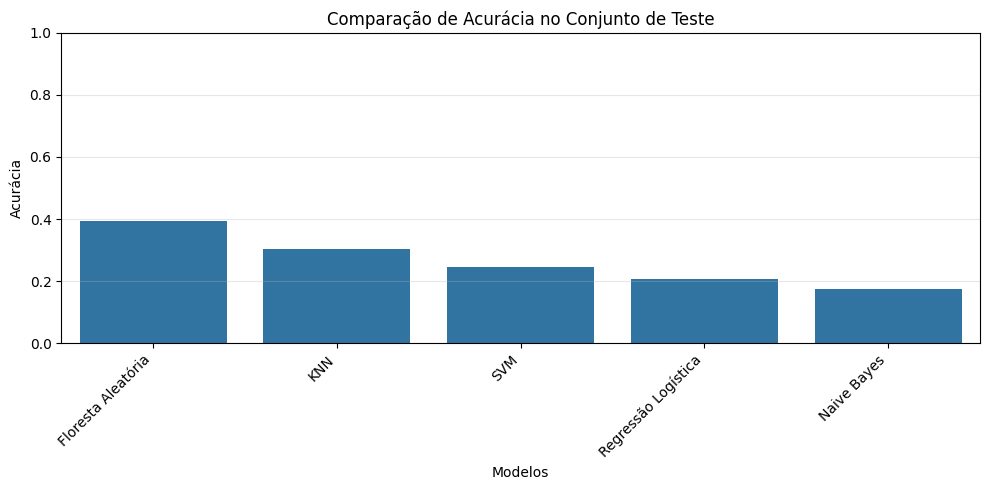

In [74]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparacao_optuna,
    x="Modelo",
    y="Acurácia no teste"
)

plt.title("Comparação de Acurácia no Conjunto de Teste")
plt.xlabel("Modelos")
plt.ylabel("Acurácia")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Vamos ver os valores de forma mais precisa:

In [75]:
comparacao_optuna = pd.DataFrame([
    {
        "Modelo": algoritmo,
        "Acurácia na validação": estudo.best_value,
        "Acurácia no teste": acuracias_teste[algoritmo],
        "Melhores hiperparâmetros": estudo.best_params
    }
    for algoritmo, estudo in estudos.items()
])

comparacao_optuna = comparacao_optuna.sort_values(
    "Acurácia no teste",
    ascending=False
).reset_index(drop=True)

display(comparacao_optuna)

,Modelo,Acurácia na validação,Acurácia no teste,Melhores hiperparâmetros
0,Floresta Aleatória,0.372993,0.393816,"{'n_estimators': 493, 'max_depth': 30, 'min_sa..."
1,KNN,0.283980,0.302763,"{'n_neighbors': 30, 'weights': 'distance', 'p'..."
2,SVM,0.204934,0.246360,"{'kernel': 'rbf', 'C': 47.90166159578758, 'gam..."
3,Regressão Logística,0.203805,0.205439,{'C': 911.2642439583799}
4,Naive Bayes,0.171853,0.175044,{'var_smoothing': 0.0009951098812182701}


Para entender melhor como está a identificação para cada gênero vamos analisar a média dos modelos das seguintes informações de cada estilo:

- **Precisão (Precision):** entre as músicas classificadas como pertencentes a determinado gênero, quantas realmente pertencem a ele?

- **Revocação (Recall):** entre todas as músicas que realmente pertencem a determinado gênero, quantas foram identificadas corretamente?

In [76]:
relatorios = []

# Média só dos modelos reais: o Baseline responde sempre a mesma classe e distorce a média
for algoritmo, y_pred in predicoes_teste.items():
    if algoritmo == "Baseline":
        continue

    relatorio = classification_report(
        y_teste,
        y_pred,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        output_dict=True,
        zero_division=0
    )

    relatorios.append(pd.DataFrame(relatorio).T)

relatorio_medio = sum(relatorios) / len(relatorios)

relatorio_medio = relatorio_medio.sort_values(
    by="f1-score",
    ascending=False
)

display(relatorio_medio)

,precision,recall,f1-score,support
comedy,0.827598,0.863,0.842506,200.0
grindcore,0.666102,0.832,0.735745,200.0
sleep,0.664403,0.775,0.710039,200.0
study,0.454517,0.798,0.575215,200.0
tango,0.460113,0.644,0.531492,200.0
...,...,...,...,...
spanish,0.092509,0.051,0.065589,200.0
indie,0.125904,0.042,0.060889,200.0
songwriter,0.110231,0.043,0.057831,200.0
goth,0.152128,0.030,0.044347,200.0


Podemos perceber que o desempenho médio varia muito para cada estilo musical. Geralmente podemos atribuir esse tipo de comportamento á vários fatores, porém nossos dados não são desbalanceados e os modelos que utilizam a ideia de distância no processo foram treinados com dados normalizados. A provável grande causa seja que estamos tentando prever uma classe dentre 114, e provavelmente existem muitas classes parecidas, vamos tentar agrupa-las e ver como isso afeta o desempenho.

## Agrupando

Temos de tomar alguns cuidados, o primeiro é que agora as classes serão agrupadas e teremos um caráter ainda maior de subjetividade em nossos modelos, pois escolheremos esses agrupamentos, fora que nossos dados serão ligeiramente desbalanceados, mas acredito que não será um fator determinante para o resultado, já que agruparemos de forma a diminuir esse efeito, outra coisa é que o rendimento tende a aumentar de qualquer forma pois até o "chute" acerta mais então não podemos comparar diretamente os desempenhos dos modelos com 114 classes e com as classes agrupadas.

Criamos a coluna `familia_musical`, que será o novo Target. O agrupamento segue dois critérios:

1. **Parentesco musical:** origem, instrumentação e andamento típico (por exemplo, `samba`, `pagode`, `forro` e `sertanejo` viram *Brasileira*; `house` e `deep-house` viram *House e dance*).

2. **Conteúdo real do rótulo:** como os rótulos nem sempre batem com o nome, a célula abaixo mostra os artistas mais frequentes de alguns gêneros ambíguos, e eles foram alocados pelo que **contêm**. Por exemplo, `j-dance` é na prática dancehall jamaicano, `reggae` é majoritariamente reggaeton, `malay` traz canções indianas e `world-music` é música cristã de louvor. A coluna `artists` é usada **apenas aqui, para conferir o agrupamento**, e não entra em nenhum modelo.

In [77]:
# Conferência (apenas leitura): artistas mais frequentes de rótulos cujo nome não bate com o conteúdo
GENEROS_PARA_CONFERIR = ["samba", "reggae", "sertanejo", "brazil", "garage", "pagode", "r-n-b", "folk"]
conferencia = []
for g in GENEROS_PARA_CONFERIR:
    top = (df.loc[df[COL_ALVO] == g, "artists"].dropna()
             .str.split(";").str[0].value_counts().head(5).index)
    conferencia.append({"gênero original": g, "artistas mais frequentes": ", ".join(top)})
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(conferencia))

,gênero original,artistas mais frequentes
0,samba,"Zeca Pagodinho, Exaltasamba, Diogo Nogueira, Akatu, Jorge Aragão"
1,reggae,"J Balvin, KAROL G, Daddy Yankee, Jhayco, Feid"
2,sertanejo,"Henrique & Juliano, Matheus & Kauan, Bruno & Marrone, Ícaro e Gilmar, Murilo Huff"
3,brazil,"Maneva, Charlie Brown Jr., O Rappa, Legião Urbana, Nando Reis"
4,garage,"Arctic Monkeys, The Strokes, The Smith Street Band, Royal Blood, The Growlers"
5,pagode,"Sorriso Maroto, Ferrugem, Turma do Pagode, Péricles, Anitta"
6,r-n-b,"Maneva, Chuck Berry, Charlie Brown Jr., Joan Sebastian, Legião Urbana"
7,folk,"Nusrat Fateh Ali Khan, Salim–Sulaiman, Kailash Kher, Prateek Kuhad, Papon"


In [78]:
FAMILIAS = {
    "Metal e industrial":             ["black-metal", "death-metal", "grindcore", "heavy-metal", "metal",
                                       "metalcore", "industrial", "groove"],
    "Rock":                           ["rock", "hard-rock", "rock-n-roll", "rockabilly", "psych-rock", "grunge"],
    "Punk e emo":                     ["punk", "punk-rock", "hardcore", "emo", "ska"],
    "Rock alternativo e indie":       ["alt-rock", "alternative", "indie", "indie-pop", "garage", "goth", "power-pop"],
    "Pop":                            ["pop", "synth-pop", "electro", "sad", "british", "french", "german",
                                       "swedish", "party"],
    "Pop e rock asiático":            ["cantopop", "mandopop", "j-pop", "j-rock", "j-idol", "anime", "k-pop"],
    "Cantautor, folk e country":      ["acoustic", "singer-songwriter", "songwriter", "country", "bluegrass",
                                       "honky-tonk"],
    "Jazz, blues e soul":             ["jazz", "blues", "soul", "funk", "disco"],
    "Hip-hop":                        ["hip-hop"],
    "Reggae e dancehall":             ["dancehall", "j-dance"],
    "Latina":                         ["latin", "latino", "reggaeton", "reggae", "salsa", "spanish", "tango",
                                       "guitar", "afrobeat"],
    "Brasileira":                     ["brazil", "mpb", "samba", "pagode", "sertanejo", "forro", "r-n-b"],
    "Gospel e música cristã":         ["gospel", "world-music"],
    "House e dance":                  ["house", "deep-house", "chicago-house", "progressive-house", "edm",
                                       "dance", "club"],
    "Techno, trance e hard dance":    ["techno", "detroit-techno", "minimal-techno", "trance", "hardstyle", "happy"],
    "Bass e eletrônica experimental": ["drum-and-bass", "dubstep", "dub", "breakbeat", "idm", "electronic",
                                       "trip-hop"],
    "Ambiente e relax":               ["ambient", "new-age", "sleep", "study", "chill"],
    "Clássica, piano e ópera":        ["classical", "piano", "opera", "romance"],
    "Infantil e entretenimento":      ["kids", "children", "disney", "show-tunes", "comedy"],
    "Índia e Oriente Médio":          ["indian", "malay", "pop-film", "folk", "iranian", "turkish"],
}

# Mapa gênero -> família. Todo gênero precisa estar em exatamente uma família
mapa_genero_familia = {}
for familia, generos in FAMILIAS.items():
    for g in generos:
        assert g not in mapa_genero_familia, f"Gênero repetido no agrupamento: {g}"
        mapa_genero_familia[g] = familia
assert set(mapa_genero_familia) == set(df[COL_ALVO].unique()), "O agrupamento não cobre exatamente os 114 gêneros"

# Novo alvo. A coluna de gênero e a de família NÃO entram nos atributos (seria vazamento de dados)
COL_ALVO_FAM = "familia_musical"
df_fam = df.assign(**{COL_ALVO_FAM: df[COL_ALVO].map(mapa_genero_familia)})

# Mesma música em dois gêneros da MESMA família vira linha duplicada com o mesmo rótulo: mantém só uma.
# Em famílias diferentes mantemos as duas (a ambiguidade faz parte do problema; a divisão por track_id evita vazamento)
antes = len(df_fam)
df_fam = df_fam.drop_duplicates(subset=[COL_GRUPO, COL_ALVO_FAM])
print(f"{len(FAMILIAS)} famílias | linhas: {antes} -> {len(df_fam)} ({antes - len(df_fam)} duplicatas removidas)")

contagem = df_fam[COL_ALVO_FAM].value_counts()
display(pd.DataFrame({"nº de gêneros": {f: len(g) for f, g in FAMILIAS.items()},
                      "nº de faixas": contagem}).sort_values("nº de faixas", ascending=False))
print(f"Maior família: {contagem.idxmax()} ({contagem.max() / len(df_fam):.1%} das faixas)")

20 famílias | linhas: 114000 -> 100834 (13166 duplicatas removidas)


,nº de gêneros,nº de faixas
Pop,9,8719
Metal e industrial,8,7347
Latina,9,6777
Pop e rock asiático,7,6224
Bass e eletrônica experimental,7,6127
Brasileira,7,5862
House e dance,7,5800
Índia e Oriente Médio,6,5783
Rock alternativo e indie,7,5583
Rock,6,5477


Maior família: Pop (8.6% das faixas)


## Nova divisão treino/teste

Como o alvo mudou (e algumas linhas foram removidas), refazemos a divisão com o mesmo critério da seção 5: `StratifiedGroupKFold`, agrupado por `track_id` (nenhuma música cai nos dois lados) e agora estratificado por **família**. Os atributos são os mesmos da seção e o alvo é codificado com um novo `LabelEncoder`.

In [79]:
# Atributos: os mesmos de antes, apenas nas linhas que sobraram
X_fam = X.loc[df_fam.index]

le_fam = LabelEncoder()
y_fam = le_fam.fit_transform(df_fam[COL_ALVO_FAM])
grupos_fam = df_fam[COL_GRUPO]

idx_treino_f, idx_teste_f = next(sgkf.split(X_fam, y_fam, groups=grupos_fam))
X_treino_f, X_teste_f = X_fam.iloc[idx_treino_f], X_fam.iloc[idx_teste_f]
y_treino_f, y_teste_f = y_fam[idx_treino_f], y_fam[idx_teste_f]

assert set(grupos_fam.iloc[idx_treino_f]).isdisjoint(set(grupos_fam.iloc[idx_teste_f]))
print("Classes:", len(le_fam.classes_), "| Treino:", X_treino_f.shape, "| Teste:", X_teste_f.shape)

proporcao = pd.DataFrame({
    "treino": pd.Series(le_fam.inverse_transform(y_treino_f)).value_counts(normalize=True),
    "teste": pd.Series(le_fam.inverse_transform(y_teste_f)).value_counts(normalize=True),
}).sort_values("treino", ascending=False)
display((proporcao * 100).round(1))

Classes: 20 | Treino: (80667, 15) | Teste: (20167, 15)


,treino,teste
Pop,8.6,8.6
Metal e industrial,7.3,7.3
Latina,6.7,6.7
Pop e rock asiático,6.2,6.2
Bass e eletrônica experimental,6.1,6.1
Brasileira,5.8,5.8
House e dance,5.8,5.8
Índia e Oriente Médio,5.7,5.7
Rock alternativo e indie,5.5,5.5
Rock,5.4,5.4


## Treinando os modelos agrupados com os hiperparâmetros já encontrados e comparando-os

Aqui não rodamos o Optuna de novo, cada modelo é treinado uma vez no novo treino, com os melhores hiperparâmetros lidos dos estudos obtidos mais acima. Reaproveitamos as mesmas funções (`normalização_padrão`, `monta_svm`, `treina_e_preve` e `treina_floresta_em_blocos`, que agora recebem os dados como argumento) e o mesmo esquema de cache, num arquivo separado para não misturar com os dados anteriores

Um ponto de atenção: esses hiperparâmetros foram otimizados para 114 classes. Com 20 famílias o ótimo pode ser um pouco diferente, então os resultados abaixo são uma estimativa conservadora do que os modelos podem render.

In [80]:
ARQUIVO_CACHE_FAM = "cache_avaliacao_teste_20_familias.joblib"
ASSINATURA_FAM = joblib.hash((idx_treino_f, idx_teste_f))

cache_fam = {}
if not REAVALIAR and Path(ARQUIVO_CACHE_FAM).exists():
    try:
        cache_fam = joblib.load(ARQUIVO_CACHE_FAM)
    except Exception:
        cache_fam = {}   # arquivo corrompido: as avaliações são refeitas

dados_f = (X_treino_f, y_treino_f, X_teste_f)

# Como construir cada modelo a partir dos hiperparâmetros da Parte I
construtores = {
    "Naive Bayes":         lambda p: normalização_padrão(GaussianNB(**p)),
    "Regressão Logística": lambda p: normalização_padrão(LogisticRegression(**p, max_iter=2000, random_state=RANDOM_STATE)),
    "SVM":                 lambda p: monta_svm(**p),
    "KNN":                 lambda p: normalização_padrão(KNeighborsClassifier(**p, n_jobs=N_JOBS_FINAL)),
}
params_fam = {"Baseline": {}, **{nome: estudos[nome].best_params for nome in estudos}}

resultados_f, predicoes_f = [], {}
for nome, params in params_fam.items():
    entrada = cache_fam.get(nome)
    if entrada and entrada["parametros"] == params and entrada["assinatura"] == ASSINATURA_FAM:
        print(f"[{nome}] carregado do cache.")
    else:
        print(f"[{nome}] treinando...")
        if nome == "Floresta Aleatória":
            y_pred, tempo, _ = treina_floresta_em_blocos(params, *dados_f)
        elif nome == "Baseline":
            y_pred, tempo, _ = treina_e_preve(DummyClassifier(strategy="most_frequent"), *dados_f)
        else:
            y_pred, tempo, _ = treina_e_preve(construtores[nome](params), *dados_f)
        entrada = {"parametros": params, "assinatura": ASSINATURA_FAM, "y_pred": y_pred, "tempo_treino_s": tempo}
        cache_fam[nome] = entrada
        joblib.dump(cache_fam, ARQUIVO_CACHE_FAM + ".tmp")
        os.replace(ARQUIVO_CACHE_FAM + ".tmp", ARQUIVO_CACHE_FAM)

    y_pred = entrada["y_pred"]
    predicoes_f[nome] = y_pred
    resultados_f.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_teste_f, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(y_teste_f, y_pred),
        "f1_macro": f1_score(y_teste_f, y_pred, average="macro"),
        "tempo_treino_s": round(entrada["tempo_treino_s"], 1),
    })

[Baseline] carregado do cache.
[Naive Bayes] carregado do cache.
[Regressão Logística] carregado do cache.
[Floresta Aleatória] carregado do cache.
[SVM] carregado do cache.
[KNN] carregado do cache.


### Comparação dos modelos com 20 famílias

A tabela está ordenada pelo **F1 macro**, que dá o mesmo peso a todas as famílias. Em seguida, comparamos a acurácia de cada modelo nas duas versões do problema. Como o piso muda (o Baseline passa de ≈0,9% para a proporção da maior família), o que importa é o **quanto cada modelo supera o seu Baseline** em cada versão, e não o valor absoluto.

,acurácia (114 gêneros),acurácia (20 famílias),ganho sobre o Baseline (114),ganho sobre o Baseline (20)
modelo,,,,
Floresta Aleatória,0.394,0.518,44.895,5.991
KNN,0.303,0.442,34.515,5.119
SVM,0.246,0.349,28.085,4.042
Regressão Logística,0.205,0.290,23.420,3.357
Naive Bayes,0.175,0.242,19.955,2.803
Baseline,0.009,0.086,1.000,1.000


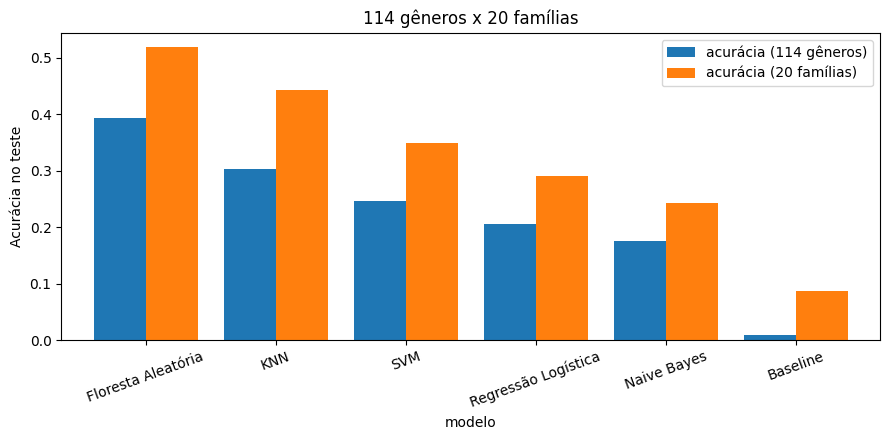

In [81]:
# Tabela da Parte I (114 gêneros)
tabela = (
    pd.DataFrame(resultados)
    .sort_values("acuracia", ascending=False)
    .reset_index(drop=True)
)

# Tabela da Parte II (20 famílias)
tabela_f = (
    pd.DataFrame(resultados_f)
    .sort_values("acuracia", ascending=False)
    .reset_index(drop=True)
)

# Comparação
comparacao = pd.DataFrame({
    "acurácia (114 gêneros)": tabela.set_index("modelo")["acuracia"],
    "acurácia (20 famílias)": tabela_f.set_index("modelo")["acuracia"],
})

comparacao["ganho sobre o Baseline (114)"] = (
    comparacao["acurácia (114 gêneros)"]
    / comparacao.loc["Baseline", "acurácia (114 gêneros)"]
)

comparacao["ganho sobre o Baseline (20)"] = (
    comparacao["acurácia (20 famílias)"]
    / comparacao.loc["Baseline", "acurácia (20 famílias)"]
)

comparacao = comparacao.sort_values(
    "acurácia (20 famílias)",
    ascending=False
)

display(comparacao.round(3))

# Gráfico
ax = comparacao[
    ["acurácia (114 gêneros)", "acurácia (20 famílias)"]
].plot.bar(
    figsize=(9, 4.5),
    rot=20,
    width=0.8
)

ax.set_ylabel("Acurácia no teste")
ax.set_title("114 gêneros x 20 famílias")

plt.tight_layout()
plt.show()

Vamos analisar na média de todos os modelos quais são as famílias mais acertadas e as mais erradas

In [82]:
# Média só dos modelos reais: o Baseline responde sempre "Pop" e inflaria a coluna Pop da matriz
modelos_reais = [m for m in predicoes_f if m != "Baseline"]

# Relatórios de classificação de cada modelo
relatorios_f = []

for algoritmo in modelos_reais:

    relatorio_f = classification_report(
        y_teste_f,
        predicoes_f[algoritmo],
        labels=np.arange(len(le_fam.classes_)),
        target_names=le_fam.classes_,
        output_dict=True,
        zero_division=0
    )

    relatorios_f.append(pd.DataFrame(relatorio_f).T)

# Média das métricas entre os modelos
relatorio_medio_f = sum(relatorios_f) / len(relatorios_f)

# Remover métricas gerais e ordenar pelo F1-score médio
por_familia = (
    relatorio_medio_f
    .drop(["accuracy", "macro avg", "weighted avg"])
    .sort_values("f1-score", ascending=False)
)

display(
    por_familia[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

# Matrizes de confusão normalizadas de cada modelo
matrizes_f = []

for algoritmo in modelos_reais:

    cm = confusion_matrix(
        y_teste_f,
        predicoes_f[algoritmo],
        labels=np.arange(len(le_fam.classes_)),
        normalize="true"
    )

    matrizes_f.append(cm)

# Média das matrizes de confusão
cm_medio_f = np.mean(matrizes_f, axis=0)

# Confusões mais frequentes: família real -> família prevista
confusoes = sorted(
    (
        (cm_medio_f[i, j], le_fam.classes_[i], le_fam.classes_[j])
        for i in range(len(cm_medio_f))
        for j in range(len(cm_medio_f))
        if i != j
    ),
    reverse=True
)

print(f"\nConfusões mais frequentes")

for valor, real, prev in confusoes[:8]:
    print(
        f"  {real} -> {prev}: "
        f"{valor:.1%} das faixas reais de '{real}'"
    )

,precision,recall,f1-score,support
Metal e industrial,0.460,0.651,0.535,1469.0
"Techno, trance e hard dance",0.499,0.578,0.534,1088.0
Ambiente e relax,0.512,0.536,0.513,996.0
Infantil e entretenimento,0.554,0.429,0.473,980.0
Brasileira,0.391,0.613,0.472,1172.0
"Clássica, piano e ópera",0.442,0.528,0.468,755.0
"Cantautor, folk e country",0.339,0.466,0.390,981.0
Gospel e música cristã,0.336,0.496,0.365,400.0
House e dance,0.314,0.418,0.356,1160.0
Latina,0.371,0.359,0.352,1356.0



Confusões mais frequentes
  Hip-hop -> Pop: 22.5% das faixas reais de 'Hip-hop'
  Rock alternativo e indie -> Metal e industrial: 19.6% das faixas reais de 'Rock alternativo e indie'
  Bass e eletrônica experimental -> Techno, trance e hard dance: 19.4% das faixas reais de 'Bass e eletrônica experimental'
  Punk e emo -> Metal e industrial: 16.6% das faixas reais de 'Punk e emo'
  House e dance -> Techno, trance e hard dance: 15.3% das faixas reais de 'House e dance'
  Ambiente e relax -> Clássica, piano e ópera: 14.8% das faixas reais de 'Ambiente e relax'
  Rock -> Metal e industrial: 14.2% das faixas reais de 'Rock'
  Clássica, piano e ópera -> Ambiente e relax: 13.9% das faixas reais de 'Clássica, piano e ópera'


Vamos visualizar isso melhor numa matriz de confusão:

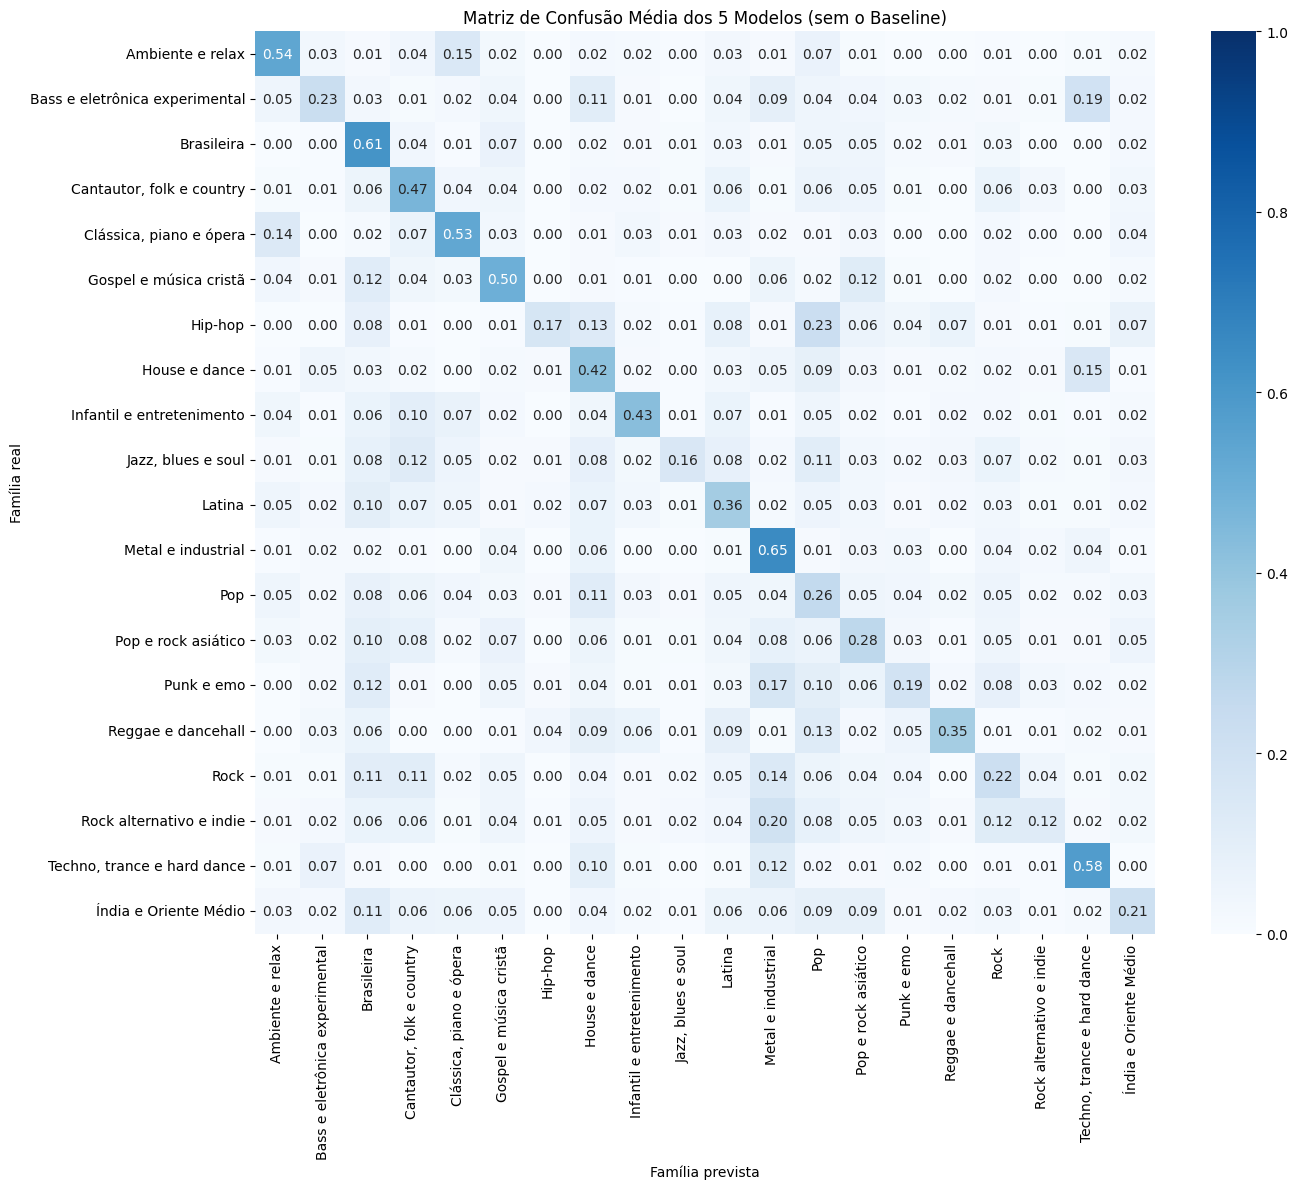

In [83]:
plt.figure(figsize=(14, 12))

sns.heatmap(
    cm_medio_f,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=le_fam.classes_,
    yticklabels=le_fam.classes_,
    vmin=0,
    vmax=1
)

plt.title("Matriz de Confusão Média dos 5 Modelos (sem o Baseline)")
plt.xlabel("Família prevista")
plt.ylabel("Família real")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Explicando os modelos: o que cada um usa para decidir?

Até aqui comparamos os modelos pelo quanto acertam. Agora queremos entender em quais atributos cada um se apoia para separar as 20 famílias. Para isso usamos a permutation importance (importância por permutação)

Com o modelo já treinado, pegamos o conjunto de teste, embaralhamos aleatoriamente os valores de **um único atributo** e medimos quanto o desempenho cai. O embaralhamento mantém a distribuição do atributo, mas quebra a relação dele com a família da música.

se o desempenho cai muito, o modelo dependia daquele atributo;

se quase não cai, o modelo não precisava dele (ou tinha outro atributo que dizia o mesmo);

se sobe um pouco, é ruído: o atributo não ajuda e o resultado oscilou ao acaso.

Repetimos o embaralhamento 3 vezes por atributo, o que nos dá uma **média** (a barra) e um **desvio** (a linha de erro). F1 macro como métrica dá o mesmo peso a todas as famílias, inclusive às pequenas, como Hip-hop.Floresta com 100 árvores. Precisamos do objeto do modelo treinado, e as 493 árvores nunca couberam inteiras na memória (por isso o treino em blocos). Mantivemos todos os outros hiperparâmetros do Optuna.

**Importância por impureza (gráfico cinza).** É a importância "de fábrica" da Floresta, calculada no treino a partir de quanto cada atributo reduz a impureza nas divisões. Ela favorece atributos contínuos com muitos valores distintos e serve de comparação com a permutação.

[Floresta Aleatória] ajustando e calculando a permutação...
   pronto em 14 s
[KNN] ajustando e calculando a permutação...
   pronto em 523 s
[SVM] ajustando e calculando a permutação...
   pronto em 65 s
[Regressão Logística] ajustando e calculando a permutação...
   pronto em 3 s
[Naive Bayes] ajustando e calculando a permutação...
   pronto em 1 s

Queda no F1 macro ao embaralhar cada atributo (amostra do teste):


,Floresta Aleatória,KNN,SVM,Regressão Logística,Naive Bayes
popularity,0.1894,0.1137,0.0607,0.0194,0.0159
instrumentalness,0.0947,0.0644,0.0397,0.0303,0.0273
acousticness,0.0861,0.0724,0.0559,0.0453,0.0113
danceability,0.0820,0.0834,0.0568,0.0408,0.0156
duration_ms,0.0675,0.0670,0.0331,0.0159,0.0071
valence,0.0545,0.0732,0.0425,0.0384,0.0115
energy,0.0435,0.0498,0.0387,0.0183,0.0011
speechiness,0.0428,0.0485,0.0222,0.0304,0.0116
tempo,0.0268,0.0607,0.0192,0.0071,0.0030
loudness,0.0267,0.0478,0.0377,0.0273,0.0107


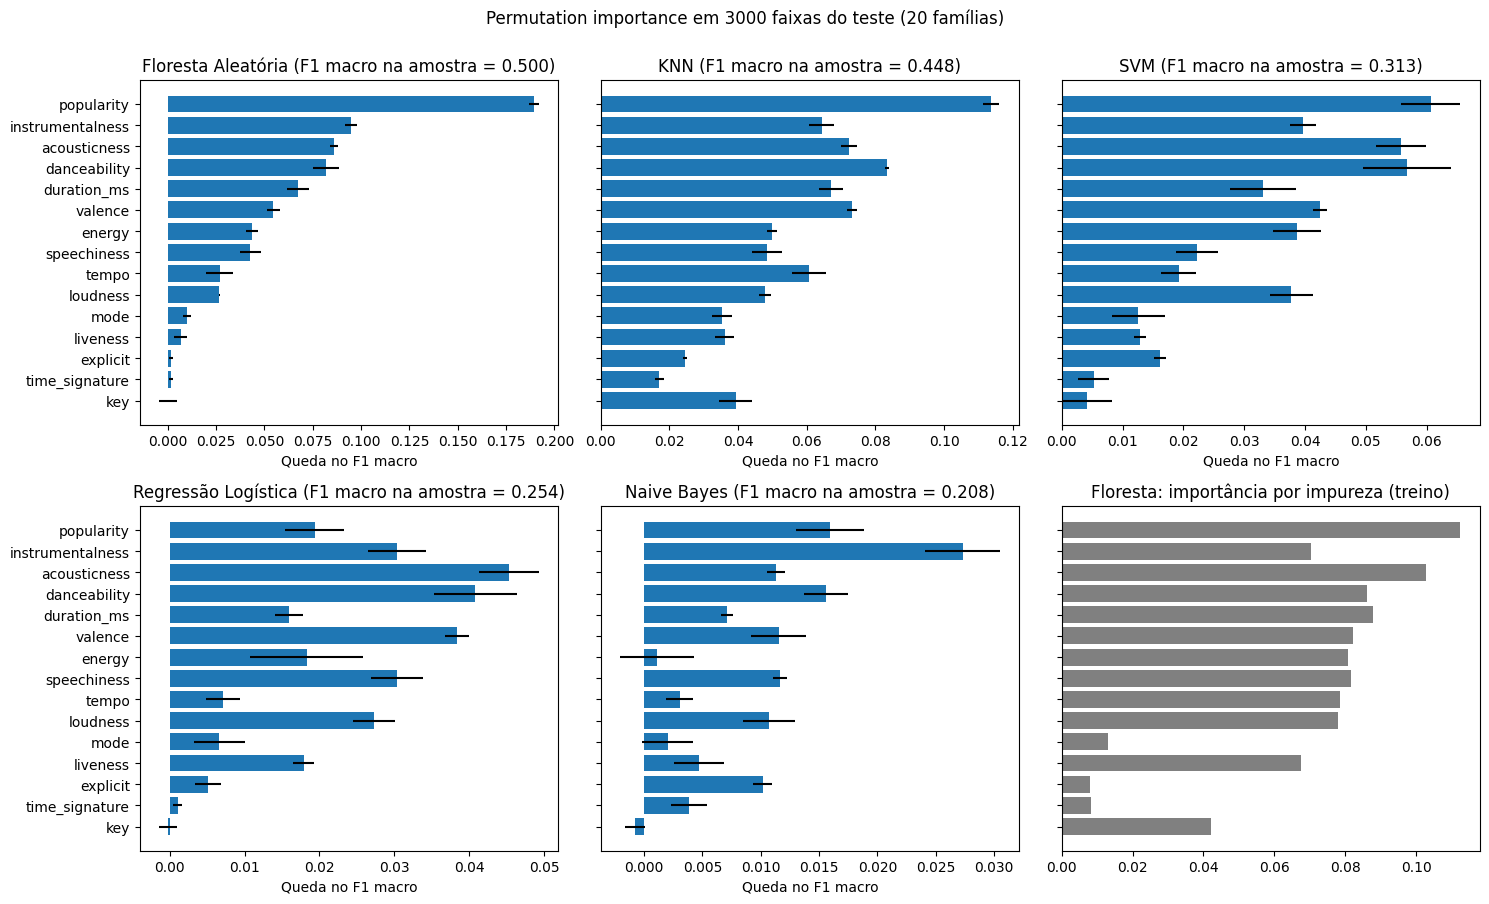

In [84]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

N_ARVORES_EXPLICACAO = 100   # Floresta: mesmos hiperparâmetros, menos árvores só para caber na memória
N_REPETICOES = 3             # vezes que cada atributo é embaralhado
N_AMOSTRA_PERM = 3000        # faixas do teste usadas na permutação (o KNN é o gargalo: o tempo é proporcional a este valor)
modelos_perm = ["Floresta Aleatória", "KNN", "SVM", "Regressão Logística", "Naive Bayes"]

# Amostra ESTRATIFICADA do teste (mantém a proporção das famílias), a mesma para todos os modelos
X_perm, _, y_perm, _ = train_test_split(X_teste_f, y_teste_f, train_size=N_AMOSTRA_PERM,
                                        stratify=y_teste_f, random_state=RANDOM_STATE)

perm_media, perm_desvio, f1_modelo = {}, {}, {}
for nome in modelos_perm:
    inicio = time.time()
    print(f"[{nome}] ajustando e calculando a permutação...")
    params = params_fam[nome]
    if nome == "Floresta Aleatória":
        modelo = RandomForestClassifier(**{**params, "n_estimators": N_ARVORES_EXPLICACAO},
                                        random_state=RANDOM_STATE, n_jobs=N_JOBS_FINAL)
    else:
        modelo = construtores[nome](params)
    modelo.fit(X_treino_f, y_treino_f)
    if nome == "Floresta Aleatória":
        imp_impureza = pd.Series(modelo.feature_importances_, index=X_perm.columns)

    f1_modelo[nome] = f1_score(y_perm, modelo.predict(X_perm), average="macro")

    # Embaralha cada atributo da amostra do TESTE e mede a queda do F1 macro
    perm = permutation_importance(modelo, X_perm, y_perm, scoring="f1_macro",
                                  n_repeats=N_REPETICOES, random_state=RANDOM_STATE, n_jobs=1)
    perm_media[nome] = pd.Series(perm.importances_mean, index=X_perm.columns)
    perm_desvio[nome] = pd.Series(perm.importances_std, index=X_perm.columns)
    del modelo
    gc.collect()
    print(f"   pronto em {time.time() - inicio:.0f} s")

# Atributos na ordem de importância da Floresta (mesma ordem em todos os gráficos)
ordem = perm_media["Floresta Aleatória"].sort_values(ascending=False).index
importancias_f = pd.DataFrame(perm_media).loc[ordem]
desvios_f = pd.DataFrame(perm_desvio).loc[ordem]
print("\nQueda no F1 macro ao embaralhar cada atributo (amostra do teste):")
display(importancias_f.round(4))

fig, eixos = plt.subplots(2, 3, figsize=(15, 9), sharey=True)
for ax, nome in zip(eixos.ravel(), modelos_perm):
    ax.barh(ordem[::-1], importancias_f.loc[ordem[::-1], nome], xerr=desvios_f.loc[ordem[::-1], nome])
    ax.set_title(f"{nome} (F1 macro na amostra = {f1_modelo[nome]:.3f})")
    ax.set_xlabel("Queda no F1 macro")
ax = eixos[1, 2]
ax.barh(ordem[::-1], imp_impureza.loc[ordem[::-1]], color="gray")
ax.set_title("Floresta: importância por impureza (treino)")
plt.suptitle(f"Permutation importance em {N_AMOSTRA_PERM} faixas do teste (20 famílias)", y=1.0)
plt.tight_layout()
plt.show()

A análise de importância por permutação indica que a variável **popularity** foi a característica mais relevante para a classificação das famílias musicais na maioria dos modelos avaliados, especialmente na **Floresta Aleatória** e no **KNN**. As variáveis **acousticness**, **danceability** e **valence** também apresentaram elevada contribuição para o desempenho dos classificadores, evidenciando a relevância de atributos relacionados às características acústicas das faixas. Em contrapartida, atributos como **key**, **time_signature** e **explicit** exerceram pouca influência sobre as predições. Entre os modelos analisados, a **Floresta Aleatória** apresentou o maior valor de F1-score macro na amostra (*0,500*), seguida pelo **KNN** (*0,448*), sugerindo maior capacidade de discriminação entre as 20 famílias musicais consideradas.

## Conclusão

Os resultados mostram que a tarefa de identificar os 114 gêneros musicais originais é bastante desafiadora. Embora a Floresta Aleatória tenha alcançado o melhor desempenho entre os modelos avaliados, com acurácia de 39,4%, a taxa de erros ainda é elevada. Observou-se também uma grande diferença entre os gêneros: alguns, como *comedy*, *grindcore* e *tango*, foram reconhecidos com facilidade devido às suas características sonoras mais marcantes, enquanto outros, como *electronic*, *indie* e *songwriter*, apresentaram forte sobreposição com gêneros semelhantes, dificultando sua distinção. Como não foram identificados indícios relevantes de sobreajuste, os resultados sugerem que a principal limitação está na semelhança entre as classes, e não na capacidade dos modelos de aprendizado.

A redução dos 114 gêneros para 20 famílias musicais tornou a tarefa mais simples e resultou em melhorias de desempenho para todos os algoritmos analisados. A Floresta Aleatória, por exemplo, aumentou sua acurácia de 39,4% para 51,8%. Entretanto, essa melhoria deve ser interpretada com cautela, pois a probabilidade de acerto ao acaso também aumentou consideravelmente devido à redução do número de classes. Mesmo assim, os resultados confirmam que o agrupamento de gêneros reduz parte da ambiguidade presente nos dados originais, tornando as fronteiras entre as categorias mais bem definidas e facilitando o trabalho dos classificadores.


Podemos visualizar isso no gráfico a seguir:

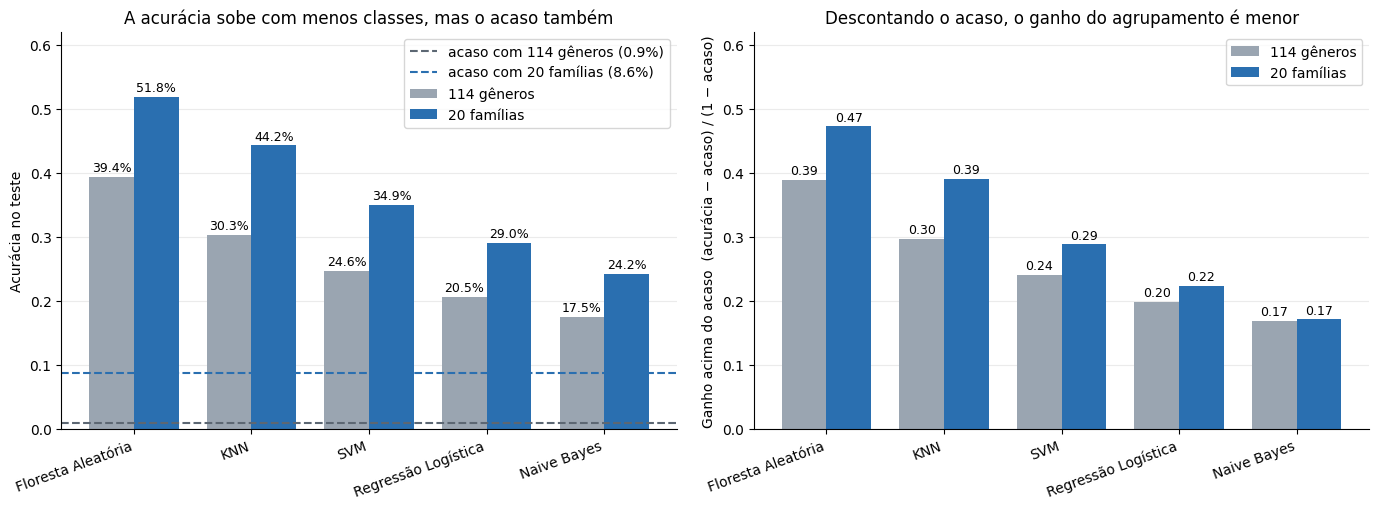

In [85]:
modelos = [m for m in comparacao.index if m != "Baseline"]
a114 = comparacao.loc[modelos, "acurácia (114 gêneros)"]
a20 = comparacao.loc[modelos, "acurácia (20 famílias)"]
acaso114 = comparacao.loc["Baseline", "acurácia (114 gêneros)"]
acaso20 = comparacao.loc["Baseline", "acurácia (20 famílias)"]

# Ganho acima do acaso: 0 = só acerta por sorte, 1 = acerta tudo
g114 = (a114 - acaso114) / (1 - acaso114)
g20 = (a20 - acaso20) / (1 - acaso20)

cor114, cor20 = "#9aa5b1", "#2a6fb0"
x = np.arange(len(modelos))
larg = 0.38

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2))

# Painel 1: acurácia e acaso
ax = eixos[0]
b1 = ax.bar(x - larg / 2, a114, larg, color=cor114, label="114 gêneros")
b2 = ax.bar(x + larg / 2, a20, larg, color=cor20, label="20 famílias")
ax.axhline(acaso114, color="#5c6773", ls="--", lw=1.5, label=f"acaso com 114 gêneros ({acaso114:.1%})")
ax.axhline(acaso20, color=cor20, ls="--", lw=1.5, label=f"acaso com 20 famílias ({acaso20:.1%})")
ax.bar_label(b1, labels=[f"{v:.1%}" for v in a114], padding=2, fontsize=9)
ax.bar_label(b2, labels=[f"{v:.1%}" for v in a20], padding=2, fontsize=9)
ax.set_xticks(x, modelos, rotation=20, ha="right")
ax.set_ylim(0, 0.62)
ax.set_ylabel("Acurácia no teste")
ax.set_title("A acurácia sobe com menos classes, mas o acaso também")
ax.legend(loc="upper right")

# Painel 2: ganho acima do acaso
ax = eixos[1]
b1 = ax.bar(x - larg / 2, g114, larg, color=cor114, label="114 gêneros")
b2 = ax.bar(x + larg / 2, g20, larg, color=cor20, label="20 famílias")
ax.bar_label(b1, labels=[f"{v:.2f}" for v in g114], padding=2, fontsize=9)
ax.bar_label(b2, labels=[f"{v:.2f}" for v in g20], padding=2, fontsize=9)
ax.set_xticks(x, modelos, rotation=20, ha="right")
ax.set_ylim(0, 0.62)
ax.set_ylabel("Ganho acima do acaso  (acurácia − acaso) / (1 − acaso)")
ax.set_title("Descontando o acaso, o ganho do agrupamento é menor")
ax.legend(loc="upper right")

for ax in eixos:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Uso de I.A

A I.A. foi utilizada neste trabalho para auxílio na escrita de códigos, principalmente no uso de ferramentas que permitiram o salvamento do processo em arquivos .Db ou .joblib, foi utilizada também para auxílio na plotagem de gráficos e para entendimento do funcionamento de alguns modelos e hiperparâmetros. Auxiliou também o uso do Optuna.

## Referências

[1] ERBETTA, L. N. de. [Esfinge: Naive Bayes]. Campinas: Ilum Escola de Ciência. Disponível em: https://github.com/drcassar/biblioteca_real.git. Acesso em 14/11/2026

[2] HASHTAG TREINAMENTOS. Regressão Logística: o que é e como funciona. [S.l.]. Disponível em: https://www.hashtagtreinamentos.com/regressao-logistica-ciencias-dados. Acesso em: 14 nov. 2026.

[3] RENA, Julio. Entendendo o algoritmo Random Forest e suas aplicações. [S.l.]: LinkedIn. Disponível em: https://pt.linkedin.com/pulse/entendendo-o-algoritmo-random-forest-e-suas-aplica%C3%A7%C3%B5es-julio-rena-aa1yc. Acesso em: 14 nov. 2026.

[4] REMIGIO, M. S. Máquinas de Vetores de Suporte (SVM). [S.l.]: Medium. Disponível em: https://medium.com/@msremigio/m%C3%A1quinas-de-vetores-de-suporte-svm-77bb114d02fc. Acesso em: 14 nov. 2026.

[5] UNITE.AI. Um guia rápido para o algoritmo KNN. [S.l.]. Disponível em: https://www.unite.ai/pt/a-quick-guide-to-knn-algorithm/. Acesso em: 14 nov. 2026.

[6]PANDYA, Maharshi. Spotify Tracks Dataset. Kaggle, [s.l.], [s.d.]. Disponível em: <https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset>. Acesso em: 8 nov. 2026.